# ECON 8876 SP 24 Session 5 (Lab)
## Instructions
Please do the following for this lab. Don't forget to upload your .ipynb file to CarmenCanvas Assignments.

In this lab session, we will use the computational tools we just learned to solve a firm investment problem.
Suppose there are two firms, firms 1 and 2. Each period they compete in quantities (i.e. Cournnot competition) where the marginal cost of firm 1 is some $c>0$ and the marginal cost of firm 2 is zero.

Assume that at the beginning of each period, firm 1 can decide to invest some amount $x \ge 0$ to reduce its cost. The total cost of investment, $rx$ for some $r>0$ is sunk and immediately incurred. If the investment is successful, marginal cost goes down by 1 next period; otherwise, marginal cost stays the same. The probability that the investment is successful is given by

$$
\Pr(c_{t+1} = c_t-1 | c_t,x_t) = \frac{\eta x_t}{1+\eta x_t} \equiv p(x_t)
$$
for some $\eta > 0$.





This combined notebook reports the Session 5 analysis for two discount factors: $\beta=0.95$ and $\beta=0.9999$.


# Preliminaries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

tol = 1e-8
maxiter = 10000
a = 200 # Demand parameter
r = 0.1 # Investment cost
eta = 1 # Probability parameter
cnum = 100 # Number of grid points for state space
xnum = 1000 # Number of grid points for choice space
cvec = np.linspace(0,99,cnum) # Grid for state space
xvec = np.linspace(0,100,xnum) # Grid for choice space

print(cvec)
# The discount factor is set separately for each specification below.


[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 54. 55. 56. 57. 58. 59. 60. 61. 62. 63. 64. 65. 66. 67. 68. 69. 70. 71.
 72. 73. 74. 75. 76. 77. 78. 79. 80. 81. 82. 83. 84. 85. 86. 87. 88. 89.
 90. 91. 92. 93. 94. 95. 96. 97. 98. 99.]


# Profit function

Hard-code Profit(c) by analytically solving for Cournot quantities and profits.

In [2]:
def Profit(c):
  q1 = (a-2*c)/3
  q2 = (a+c)/3
  price = a-(q1+q2)
  Profit = price*q1 - c*q1 # (a-2*c)^2/9 = q1^2
  return Profit

print(Profit(0))

4444.444444444444


# Bellman operator given V0

Create a function that returns the Bellman operator given a vector V0.

In [3]:
def prob(x):
    prob = (eta*x)/(1+eta*x)
    return prob

def bellman(V0):
    xmat = xvec[np.newaxis,:].repeat(1,1)
    cmat = np.repeat(cvec.reshape(cnum,1),xnum,1)
    V0mat = np.repeat(V0.reshape(cnum,1),xnum,1)
    V0Tmat = np.vstack([V0mat[0],V0mat[0:cnum-1]])

    V1mat = Profit(cmat) - r*xmat + beta*(prob(xmat)*V0Tmat + (1-prob(xmat))*V0mat)
    V1 = np.amax(V1mat,axis=1,keepdims=False)
    x1 = xvec[np.argmax(V1mat,axis=1)]
    return V1, x1

# Results for $\beta=0.95$


In [ ]:
beta = 0.95
print(f"Discount factor: {beta}")


# Value function iteration

Solve the model using value function iteration. Plot the value and policy functions if the algorithm converges below the maximum number of iterations. Otherwise, indicate that max number of iterations reached. If your code converges, how many iterations did it take?

Convergence reached after  523  iterations


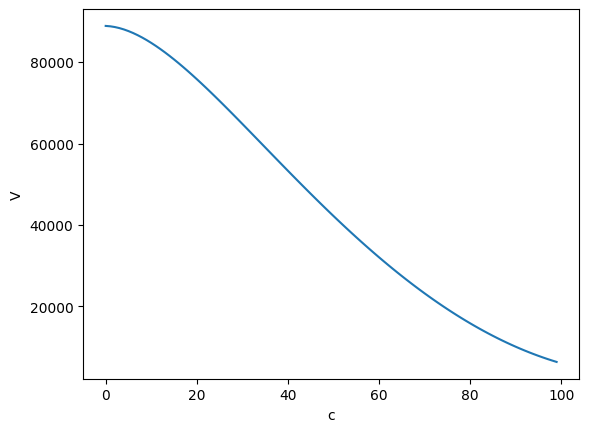

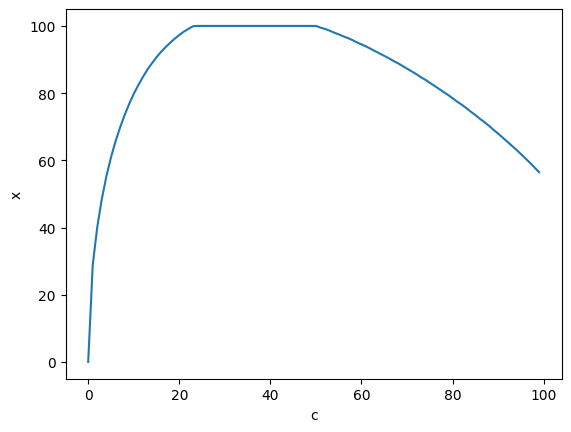

In [4]:
V0 = np.zeros(cnum)
for iter in range(maxiter):
    V1, x1 = bellman(V0)
    diff = abs(V1-V0)
    if np.all(diff < tol):
      print('Convergence reached after ', iter, ' iterations')

      plt.plot(cvec,V1)
      plt.xlabel('c')
      plt.ylabel('V')
      plt.show()

      plt.plot(cvec,x1)
      plt.xlabel('c')
      plt.ylabel('x')
      plt.show()
      break
    V0 = V1
else:
    print('Max iter reached')

# Policy function iteration

Solve the model using policy function iteration. Plot the value and policy functions if the algorithm converges below the maximum number of iterations. Otherwise, indicate that max number of iterations reached. If your code converges, how many iterations did it take?

Convergence reached after  4  iterations


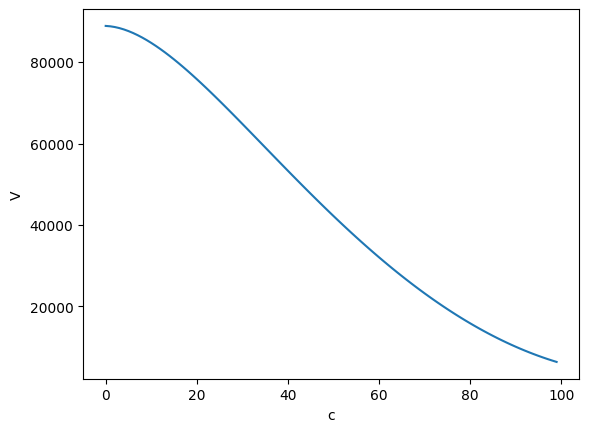

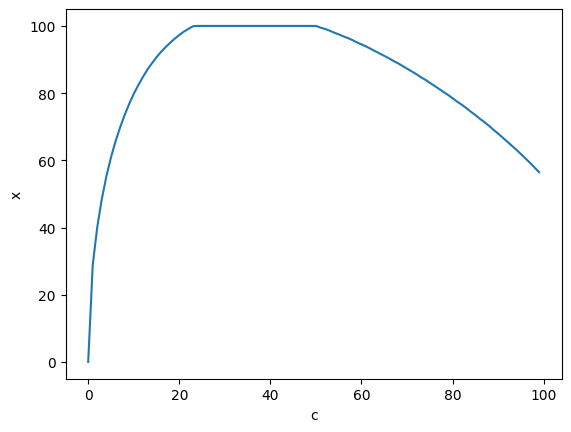

In [5]:
V0 = np.zeros(cnum)
for iter in range(maxiter):
    V1temp, x1 = bellman(V0)
    U = Profit(cvec)-r*x1
    Q = np.diag(1-prob(x1))+np.diag(prob(x1),-1)[1:,1:]
    V1 = np.linalg.inv((np.identity(cnum) - beta*Q))@U
    diff = abs(V1-V0)
    if np.all(diff < tol):
      print('Convergence reached after ', iter, ' iterations')

      plt.plot(cvec,V1)
      plt.xlabel('c')
      plt.ylabel('V')
      plt.show()

      plt.plot(cvec,x1)
      plt.xlabel('c')
      plt.ylabel('x')
      plt.show()
      break
    V0 = V1
else:
    print('Max iter reached')

# Results for $\beta=0.9999$


In [ ]:
beta = 0.9999
print(f"Discount factor: {beta}")


# Value function iteration

Solve the model using value function iteration. Plot the value and policy functions if the algorithm converges below the maximum number of iterations. Otherwise, indicate that max number of iterations reached. If your code converges, how many iterations did it take?

In [10]:
V0 = np.zeros(cnum)
for iter in range(maxiter):
    V1, x1 = bellman(V0)
    diff = abs(V1-V0)
    if np.all(diff < tol):
      print('Convergence reached after ', iter, ' iterations')

      plt.plot(cvec,V1)
      plt.xlabel('c')
      plt.ylabel('V')
      plt.show()

      plt.plot(cvec,x1)
      plt.xlabel('c')
      plt.ylabel('x')
      plt.show()
      break
    V0 = V1
else:
    print('Max iter reached')

Max iter reached


# Policy function iteration

Solve the model using policy function iteration. Plot the value and policy functions if the algorithm converges below the maximum number of iterations. Otherwise, indicate that max number of iterations reached. If your code converges, how many iterations did it take?

Convergence reached after  4  iterations


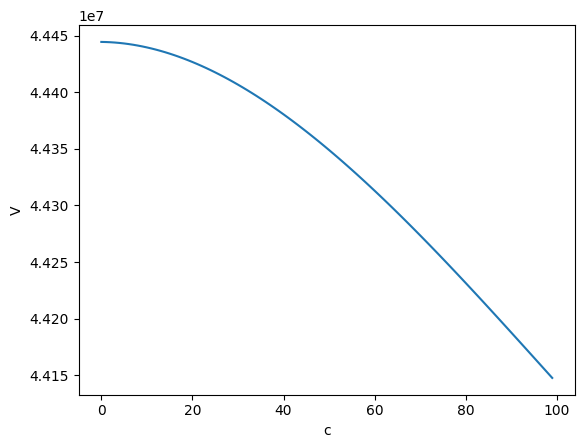

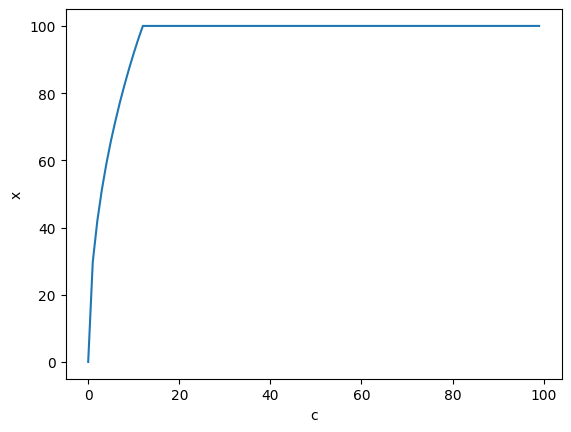

In [11]:
V0 = np.zeros(cnum)
for iter in range(maxiter):
    V1temp, x1 = bellman(V0)
    U = Profit(cvec)-r*x1
    Q = np.diag(1-prob(x1))+np.diag(prob(x1),-1)[1:,1:]
    V1 = np.linalg.inv((np.identity(cnum) - beta*Q))@U
    diff = abs(V1-V0)
    if np.all(diff < tol):
      print('Convergence reached after ', iter, ' iterations')

      plt.plot(cvec,V1)
      plt.xlabel('c')
      plt.ylabel('V')
      plt.show()

      plt.plot(cvec,x1)
      plt.xlabel('c')
      plt.ylabel('x')
      plt.show()
      break
    V0 = V1
else:
    print('Max iter reached')